# Ölçüm cihazı farkı ayırt edebiliyor mu?

Yeni ambalajın ölçüsünde küçük fark aranıyor. Ancak cetvel, operatör ve tekrar oynaklığı bu farkı örtebilir. 12 parça, üç operatör, üç tekrar ile çapraz ölçülüyor. Birinci senaryo daha kararlı; ikincisinde tekrar hatası büyüyor. Gerçek süreç farkı demeden önce ölçüm sisteminin katkısı ayrılmalı.

**Karar:** Bu ölçüm sistemi küçük süreç farklarını izlemek için yeterli mi; hangi hata kaynağı araştırılmalı?

**Birim:** Parça × operatör × tekrar hücresindeki ölçüm. Hedef: parça ile ölçüm sistemi varyans bileşenleri.

**Yöntem:** Dengeli çapraz iki faktörlü ANOVA ile parça, operatör, etkileşim ve hücre içi hatayı ayır. Moment formüllerinden varyans bileşenlerini kur; SD oranıyla varyans oranını karıştırma. Eşiklerin kaynağını açıkça belirt.

Veriler sabit tohumla üretilmiş sentetiktir; gerçek şirket veya kişi verisi değildir. Python paket sürümleri ZIP içindeki requirements.txt dosyasındadır. Her senaryo kendi verisini üretir; CSV dosyaları hazır örneklerle birlikte verilir.


## Senaryo: Daha düşük tekrar hatası

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                        Ölçü      Değer
   Parça × operatör × tekrar 12 × 3 × 3
            Gage R&R SD · mm    0.24415
           % study variation  15.643433
     % variance contribution    2.44717
% tolerance · genişlik 10 mm   14.64897
          ndc · örnek tahmin          8

Dengeli çapraz ANOVA
        source         SS  df        MS
         Parça 235.400781  11 21.400071
      Operatör   2.729838   2  1.364919
Parça×operatör   0.309128  22  0.014051
 Tekrar hatası   1.590112  72  0.022085

Negatif moment tahminleri 0’a kırpılmış bileşenler
    component  variance       SD
Repeatability  0.022085 0.148610
     Operator  0.037524 0.193711
  Interaction  0.000000 0.000000
         Part  2.376224 1.541501

Karar: Bu eğitim vakasının önceden seçilmiş iç ölçütleri (%study≤20 ve %tolerans≤15) sağlandı.

Sınır: Dengeli, çapraz, rastgele etkili ANOVA moment yaklaşımı; parça ve operatör temsili, sabit varyans ve kararlılık varsayımları gerekir. İç eşikler öğretim senaryosudur, evrensel s

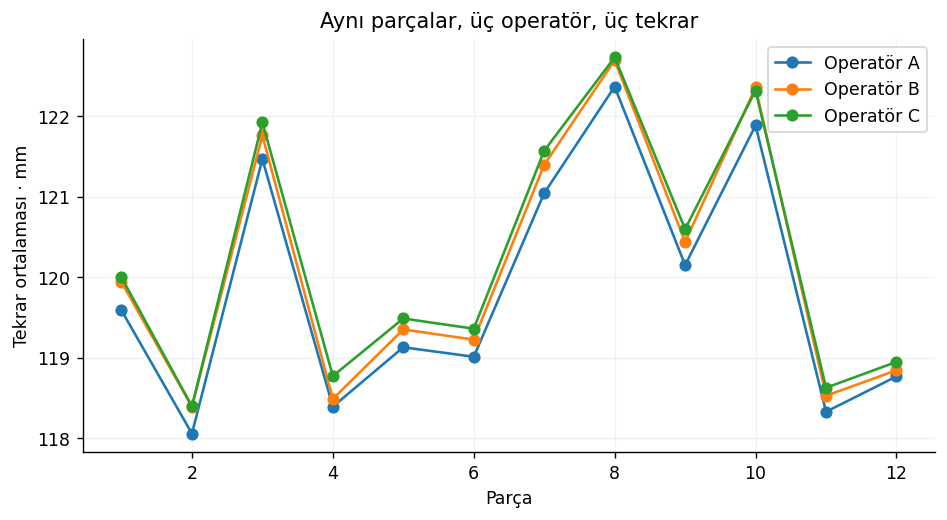

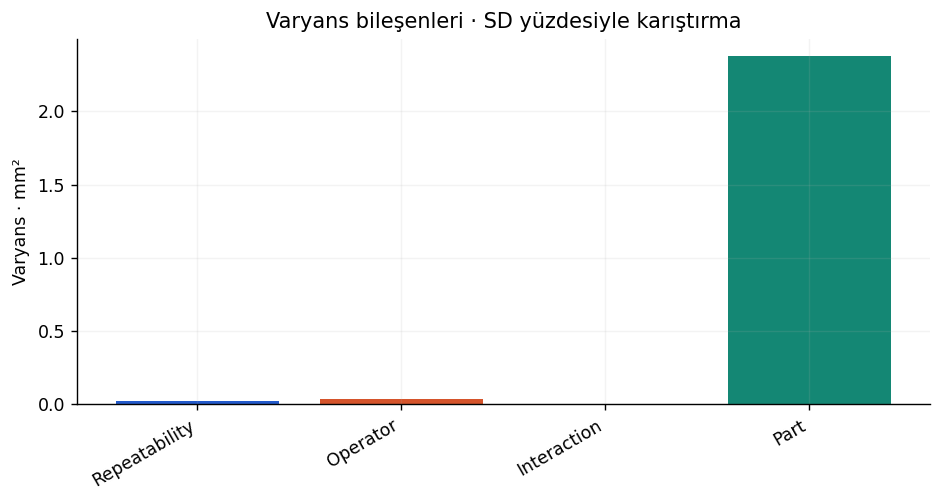

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def gage(scenario='default'):
 rng=np.random.default_rng(260805);parts,operators,repeats=12,3,3;truth=rng.normal(120,1.8,parts);offset=np.array([-.2,.05,.15]);interaction=rng.normal(0,.07,(parts,operators));sigma=.15 if scenario=='default' else .65;rows=[]
 for i in range(parts):
  for j in range(operators):
   for r in range(repeats):rows.append([str(i+1),['A','B','C'][j],r+1,truth[i]+offset[j]+interaction[i,j]+rng.normal(0,sigma)])
 raw=pd.DataFrame(rows,columns=['part','operator','repeat','millimeters']);raw=raw.iloc[rng.permutation(len(raw))].reset_index(drop=True);raw['measurement_order']=np.arange(1,len(raw)+1);grand=raw.millimeters.mean();pm=raw.groupby('part').millimeters.mean();om=raw.groupby('operator').millimeters.mean();cm=raw.groupby(['part','operator']).millimeters.mean();ssp=operators*repeats*np.sum((pm-grand)**2);sso=parts*repeats*np.sum((om-grand)**2);ssi=repeats*sum((cm.loc[i,j]-pm.loc[i]-om.loc[j]+grand)**2 for i,j in cm.index);sse=sum((row.millimeters-cm.loc[row.part,row.operator])**2 for row in raw.itertuples());dfs=np.array([parts-1,operators-1,(parts-1)*(operators-1),parts*operators*(repeats-1)]);ss=np.array([ssp,sso,ssi,sse]);ms=ss/dfs
 # Independent reference through balanced two-factor OLS ANOVA.
 ref=sm.stats.anova_lm(smf.ols('millimeters ~ C(part)*C(operator)',raw).fit(),typ=2);assert np.allclose(ss,ref['sum_sq'].values,rtol=1e-8,atol=1e-8)
 ve=ms[3];vpo=max(0,(ms[2]-ms[3])/repeats);vo=max(0,(ms[1]-ms[2])/(parts*repeats));vp=max(0,(ms[0]-ms[2])/(operators*repeats));rr=ve+vpo+vo;total=rr+vp;sdrr=np.sqrt(rr);study=100*np.sqrt(rr/total);contrib=100*rr/total;tolerance=10.;ptol=100*6*sdrr/tolerance;ndc=int(np.floor(1.41*np.sqrt(vp)/sdrr));table=pd.DataFrame({'source':['Parça','Operatör','Parça×operatör','Tekrar hatası'],'SS':ss,'df':dfs,'MS':ms});comp=pd.DataFrame({'component':['Repeatability','Operator','Interaction','Part'],'variance':[ve,vo,vpo,vp],'SD':np.sqrt([ve,vo,vpo,vp])});reference_thresholds={'study_percent':20,'tolerance_percent':15};decision='Bu eğitim vakasının önceden seçilmiş iç ölçütleri (%study≤20 ve %tolerans≤15) '+('sağlandı.'if study<=20 and ptol<=15 else'sağlanmadı; cihaz/operatör/uygulama kaynağını iyileştirmeden küçük süreç farklarına güvenme.')
 fig,ax=plt.subplots();means=raw.groupby(['part','operator']).millimeters.mean().unstack('operator').reindex([str(i+1)for i in range(parts)])
 for name in means.columns:ax.plot(range(1,parts+1),means[name],'o-',label='Operatör '+name)
 ax.set(xlabel='Parça',ylabel='Tekrar ortalaması · mm',title='Aynı parçalar, üç operatör, üç tekrar');ax.legend()
 fig2,ax2=plt.subplots();ax2.bar(comp.component,comp.variance,color=['#235ACB','#D5542B','#BE8D28','#148774']);ax2.set(ylabel='Varyans · mm²',title='Varyans bileşenleri · SD yüzdesiyle karıştırma');fig2.autofmt_xdate()
 return dict(metrics={'Parça × operatör × tekrar':'12 × 3 × 3','Gage R&R SD · mm':sdrr,'% study variation':study,'% variance contribution':contrib,'% tolerance · genişlik 10 mm':ptol,'ndc · örnek tahmin':ndc},tables=[tbl(table,'Dengeli çapraz ANOVA'),tbl(comp,'Negatif moment tahminleri 0’a kırpılmış bileşenler')],figures=[('Parça etkisini operatör ve tekrar katkısından ayırmak için aynı parçalar çapraz ölçülür.',fig),('Toplam varyans bileşenlerinin toplama kuralı SD’lere doğrudan uygulanmaz.',fig2)],frames={'capraz_olcumler':raw},steps=['Temsil edici 12 parça, üç operatör, her hücrede üç tekrar; ölçüm sırası rastgele.','Dengeli iki faktörlü ANOVA’da parça, operatör, etkileşim ve hücre içi hatanın SS/df/MS değerlerini ayır.','σ²e=MSerror; σ²etkileşim=(MSint−MSerror)/r; σ²operatör=(MSop−MSint)/(p×r); σ²parça=(MSpart−MSint)/(o×r). Negatif moment tahminleri sıfıra kırpılır.','RR varyansı tekrar+operatör+etkileşimdir. %study SD oranıdır; %contribution varyans oranıdır. Tolerans yüzdesi 6×SD_RR/tolerans genişliğidir.'],decision=decision,diagnostics={'ss':ss.tolist(),'ols_ss':ref['sum_sq'].values.tolist(),'variances':{'repeat':ve,'operator':vo,'interaction':vpo,'part':vp},'study_percent':study,'contribution_percent':contrib,'tolerance_percent':ptol,'ndc':ndc,'n':len(raw),'thresholds':reference_thresholds},limit='Dengeli, çapraz, rastgele etkili ANOVA moment yaklaşımı; parça ve operatör temsili, sabit varyans ve kararlılık varsayımları gerekir. İç eşikler öğretim senaryosudur, evrensel standart değildir. Bileşen güven aralıkları/negatif tahmin belirsizliği burada hesaplanmaz; etkileşim havuzlanmaz.')

result=gage('default')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Senaryo: Yüksek tekrar hatası

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                        Ölçü      Değer
   Parça × operatör × tekrar 12 × 3 × 3
            Gage R&R SD · mm   0.711421
           % study variation  41.428999
     % variance contribution  17.163619
% tolerance · genişlik 10 mm  42.685288
          ndc · örnek tahmin          3

Dengeli çapraz ANOVA
        source         SS  df        MS
         Parça 244.738564  11 22.248960
      Operatör   7.111636   2  3.555818
Parça×operatör   5.826927  22  0.264860
 Tekrar hatası  29.858762  72  0.414705

Negatif moment tahminleri 0’a kırpılmış bileşenler
    component  variance       SD
Repeatability  0.414705 0.643976
     Operator  0.091415 0.302350
  Interaction  0.000000 0.000000
         Part  2.442678 1.562907

Karar: Bu eğitim vakasının önceden seçilmiş iç ölçütleri (%study≤20 ve %tolerans≤15) sağlanmadı; cihaz/operatör/uygulama kaynağını iyileştirmeden küçük süreç farklarına güvenme.

Sınır: Dengeli, çapraz, rastgele etkili ANOVA moment yaklaşımı; parça ve operatör temsili, sabit vary

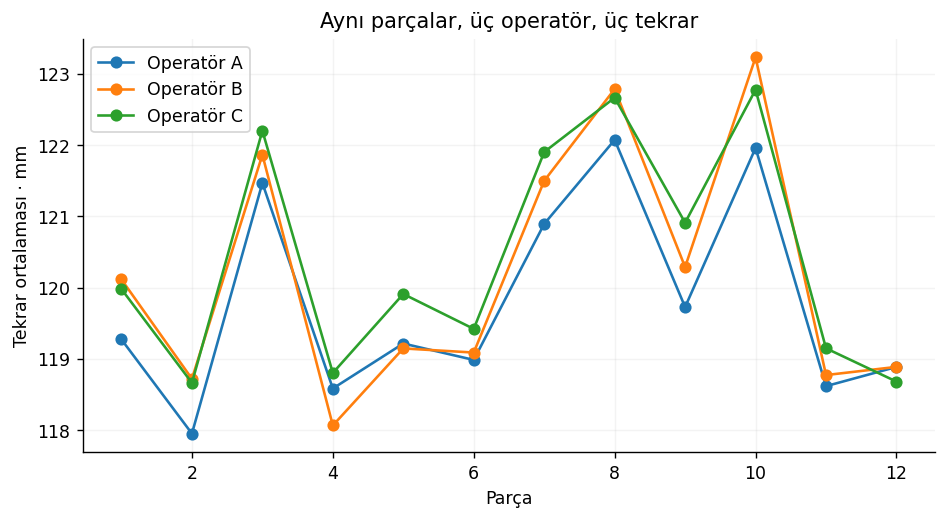

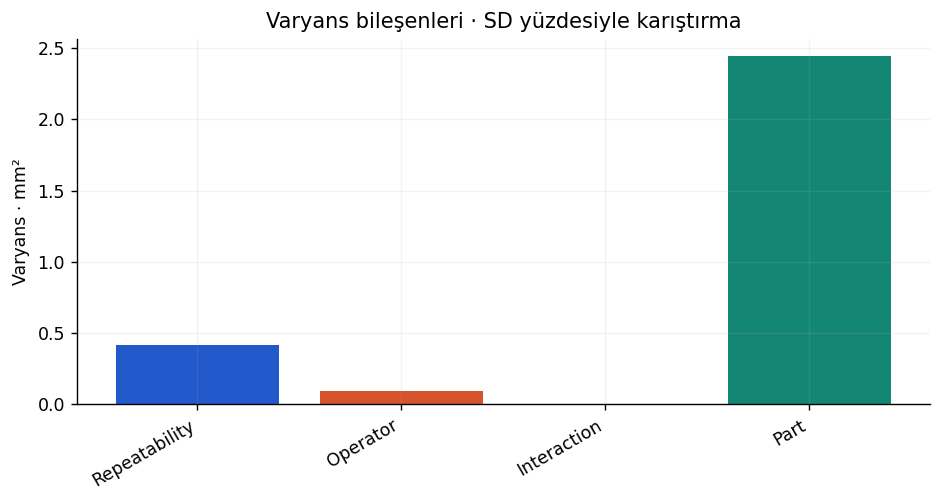

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def gage(scenario='default'):
 rng=np.random.default_rng(260805);parts,operators,repeats=12,3,3;truth=rng.normal(120,1.8,parts);offset=np.array([-.2,.05,.15]);interaction=rng.normal(0,.07,(parts,operators));sigma=.15 if scenario=='default' else .65;rows=[]
 for i in range(parts):
  for j in range(operators):
   for r in range(repeats):rows.append([str(i+1),['A','B','C'][j],r+1,truth[i]+offset[j]+interaction[i,j]+rng.normal(0,sigma)])
 raw=pd.DataFrame(rows,columns=['part','operator','repeat','millimeters']);raw=raw.iloc[rng.permutation(len(raw))].reset_index(drop=True);raw['measurement_order']=np.arange(1,len(raw)+1);grand=raw.millimeters.mean();pm=raw.groupby('part').millimeters.mean();om=raw.groupby('operator').millimeters.mean();cm=raw.groupby(['part','operator']).millimeters.mean();ssp=operators*repeats*np.sum((pm-grand)**2);sso=parts*repeats*np.sum((om-grand)**2);ssi=repeats*sum((cm.loc[i,j]-pm.loc[i]-om.loc[j]+grand)**2 for i,j in cm.index);sse=sum((row.millimeters-cm.loc[row.part,row.operator])**2 for row in raw.itertuples());dfs=np.array([parts-1,operators-1,(parts-1)*(operators-1),parts*operators*(repeats-1)]);ss=np.array([ssp,sso,ssi,sse]);ms=ss/dfs
 # Independent reference through balanced two-factor OLS ANOVA.
 ref=sm.stats.anova_lm(smf.ols('millimeters ~ C(part)*C(operator)',raw).fit(),typ=2);assert np.allclose(ss,ref['sum_sq'].values,rtol=1e-8,atol=1e-8)
 ve=ms[3];vpo=max(0,(ms[2]-ms[3])/repeats);vo=max(0,(ms[1]-ms[2])/(parts*repeats));vp=max(0,(ms[0]-ms[2])/(operators*repeats));rr=ve+vpo+vo;total=rr+vp;sdrr=np.sqrt(rr);study=100*np.sqrt(rr/total);contrib=100*rr/total;tolerance=10.;ptol=100*6*sdrr/tolerance;ndc=int(np.floor(1.41*np.sqrt(vp)/sdrr));table=pd.DataFrame({'source':['Parça','Operatör','Parça×operatör','Tekrar hatası'],'SS':ss,'df':dfs,'MS':ms});comp=pd.DataFrame({'component':['Repeatability','Operator','Interaction','Part'],'variance':[ve,vo,vpo,vp],'SD':np.sqrt([ve,vo,vpo,vp])});reference_thresholds={'study_percent':20,'tolerance_percent':15};decision='Bu eğitim vakasının önceden seçilmiş iç ölçütleri (%study≤20 ve %tolerans≤15) '+('sağlandı.'if study<=20 and ptol<=15 else'sağlanmadı; cihaz/operatör/uygulama kaynağını iyileştirmeden küçük süreç farklarına güvenme.')
 fig,ax=plt.subplots();means=raw.groupby(['part','operator']).millimeters.mean().unstack('operator').reindex([str(i+1)for i in range(parts)])
 for name in means.columns:ax.plot(range(1,parts+1),means[name],'o-',label='Operatör '+name)
 ax.set(xlabel='Parça',ylabel='Tekrar ortalaması · mm',title='Aynı parçalar, üç operatör, üç tekrar');ax.legend()
 fig2,ax2=plt.subplots();ax2.bar(comp.component,comp.variance,color=['#235ACB','#D5542B','#BE8D28','#148774']);ax2.set(ylabel='Varyans · mm²',title='Varyans bileşenleri · SD yüzdesiyle karıştırma');fig2.autofmt_xdate()
 return dict(metrics={'Parça × operatör × tekrar':'12 × 3 × 3','Gage R&R SD · mm':sdrr,'% study variation':study,'% variance contribution':contrib,'% tolerance · genişlik 10 mm':ptol,'ndc · örnek tahmin':ndc},tables=[tbl(table,'Dengeli çapraz ANOVA'),tbl(comp,'Negatif moment tahminleri 0’a kırpılmış bileşenler')],figures=[('Parça etkisini operatör ve tekrar katkısından ayırmak için aynı parçalar çapraz ölçülür.',fig),('Toplam varyans bileşenlerinin toplama kuralı SD’lere doğrudan uygulanmaz.',fig2)],frames={'capraz_olcumler':raw},steps=['Temsil edici 12 parça, üç operatör, her hücrede üç tekrar; ölçüm sırası rastgele.','Dengeli iki faktörlü ANOVA’da parça, operatör, etkileşim ve hücre içi hatanın SS/df/MS değerlerini ayır.','σ²e=MSerror; σ²etkileşim=(MSint−MSerror)/r; σ²operatör=(MSop−MSint)/(p×r); σ²parça=(MSpart−MSint)/(o×r). Negatif moment tahminleri sıfıra kırpılır.','RR varyansı tekrar+operatör+etkileşimdir. %study SD oranıdır; %contribution varyans oranıdır. Tolerans yüzdesi 6×SD_RR/tolerans genişliğidir.'],decision=decision,diagnostics={'ss':ss.tolist(),'ols_ss':ref['sum_sq'].values.tolist(),'variances':{'repeat':ve,'operator':vo,'interaction':vpo,'part':vp},'study_percent':study,'contribution_percent':contrib,'tolerance_percent':ptol,'ndc':ndc,'n':len(raw),'thresholds':reference_thresholds},limit='Dengeli, çapraz, rastgele etkili ANOVA moment yaklaşımı; parça ve operatör temsili, sabit varyans ve kararlılık varsayımları gerekir. İç eşikler öğretim senaryosudur, evrensel standart değildir. Bileşen güven aralıkları/negatif tahmin belirsizliği burada hesaplanmaz; etkileşim havuzlanmaz.')

result=gage('noisy')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Uygula ve karar notu

Yüksek hata senaryosunda %study ile %variance contribution değerlerini karşılaştır. Neden eşit olmadıklarını SD/varyans üzerinden açıkla.

Kabul ölçütleri: analiz birimini doğru tanımla; yöntem seçimini gerekçelendir; etkiyi/aralığı doğal birimle raporla; varsayımı ve bir sonraki veri ihtiyacını yaz.
